# Homework

In [2]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

## Problems [Part 1](./01_Catch_Motion.md)

**1.** Instead of using $\frac{\Delta v}{\Delta t}$, you can use the [numpy polyfit](https://docs.scipy.org/doc/numpy/reference/generated/numpy.polyfit.html) to determine the acceleration of the ball. 

a. Use your coordinates from the saved .npz file you used above to load your projectile motion data

```python
npz_coords = np.load('projectile_coords.npz')
t = npz_coords['t']
x = npz_coords['x']
y = npz_coords['y']
```

c. Use a second-order polynomial fit for x- and y- vs t. What is acceleration now?

d. Plot the polyfit lines for position and time (2 figures) with the
positions vs time. Do the fits match the data?

In [38]:
#a
npz_coords = np.load("../data/projectile_coords.npz")
t = npz_coords['t']
x = npz_coords['x']
y = npz_coords['y']

In [39]:
#c
x1,x2,x3 = np.polyfit(t, x, 2)
y1,y2,y3 = np.polyfit(t, y, 2)

print(f"x acceleration: {2*x1} m/s^2")
print(f"y acceleration: {2*y1} m/s^2")

x acceleration: 0.03773050983351923 m/s^2
y acceleration: -10.222138376644812 m/s^2


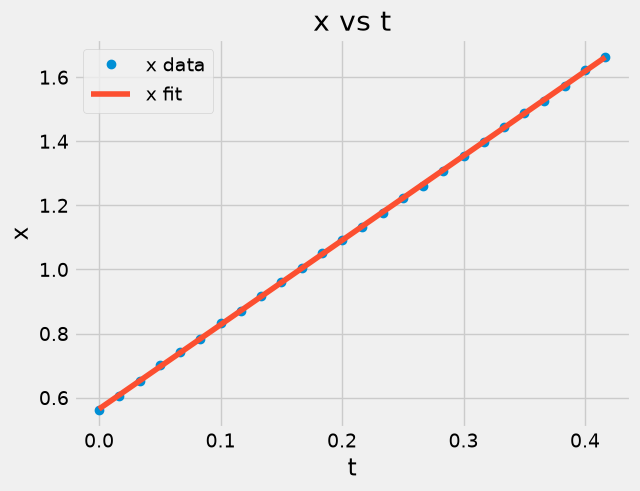

In [40]:
plt.plot(t, x, 'o', label='x data')
plt.xlabel('t')
plt.ylabel('x')
x_fit = x1*t**2 + x2*t + x3
plt.plot(t, x_fit, label='x fit')
plt.title('x vs t')
plt.legend()


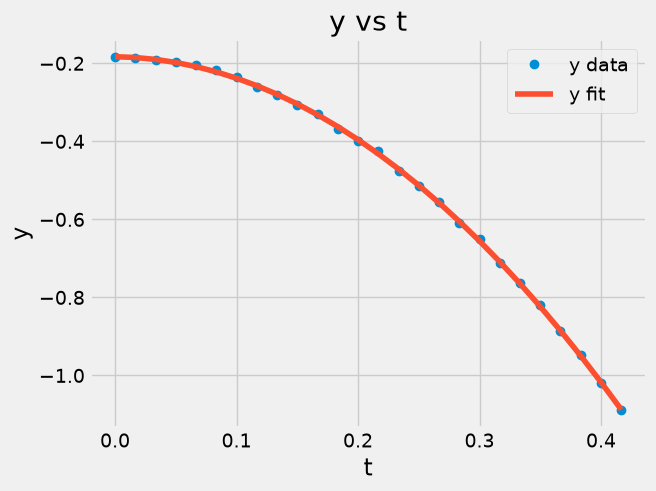

In [41]:
plt.plot(t, y, 'o', label='y data')
plt.xlabel('t')
plt.ylabel('y')
y_fit = y1*t**2 + y2*t + y3
plt.plot(t, y_fit, label='y fit')
plt.title('y vs t')
plt.legend()

Both fits match the data closely. The x acceleration is close to zero and the y acceleration is about -10.22 m/s^2.

**2.** Not only can you measure acceleration of objects that you track, you can look at other physical constants like [coefficient of restitution](https://en.wikipedia.org/wiki/Coefficient_of_restitution), $e$ . 

     During a collision with the ground, the coefficient of restitution is
     
     $e = -\frac{v_{y}'}{v_{y}}$ . 
     
     Where $v_y'$ is y-velocity perpendicular to the ground after impact
     and $v_y$ is the y-velocity before impact. 
     
a. Calculate $v_y$ and plot as a function of time from the data `'../data/fallingtennisball02.txt'`

b. Find the locations when $v_y$ changes rapidly i.e. the impact locations. Get the maximum and minimum velocities closest to the impact location. _Hint: this can be a little tricky. Try slicing the data to include one collision at a time before using  the `np.min` and `np.max` commands._

c. Calculate the $e$ for each of the three collisions

In [42]:
fallingtennisball = np.genfromtxt("../data/fallingtennisball02.txt")

In [43]:
y = fallingtennisball[:,1]
t = fallingtennisball[:,0]
v_y = np.gradient(y, t)

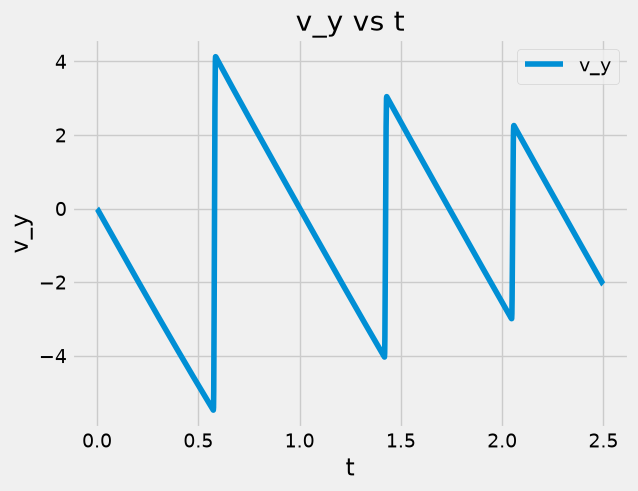

In [44]:
plt.plot(t, v_y, label='v_y')
plt.xlabel('t')
plt.ylabel('v_y')
plt.title('v_y vs t')
plt.legend()

In [45]:
#b,c
collision_ranges = [(0.5, 0.7), (1.35, 1.5), (2.0, 2.15)]

for i, (t0, t1) in enumerate(collision_ranges):
    collision = (t >= t0) & (t <= t1)
    min_v_y = np.min(v_y[collision])
    max_v_y = np.max(v_y[collision])
    impact_time = t[collision][np.argmin(y[collision])]
    cof_rest = -max_v_y / min_v_y
    print(f"Collision {i+1} at {impact_time:.3f} s")
    print(f"Minimum v_y: {min_v_y:.4f} m/s")
    print(f"Maximum v_y: {max_v_y:.4f} m/s")
    print(f"Coefficient of restitution: {cof_rest:.4f}")

Collision 1 at 0.580 s
Minimum v_y: -5.4815 m/s
Maximum v_y: 4.1282 m/s
Coefficient of restitution: 0.7531
Collision 2 at 1.425 s
Minimum v_y: -4.0384 m/s
Maximum v_y: 3.0424 m/s
Coefficient of restitution: 0.7534
Collision 3 at 2.052 s
Minimum v_y: -2.9943 m/s
Maximum v_y: 2.2570 m/s
Coefficient of restitution: 0.7538


## Problems [Part 2](./02_Step_Future.md)

**1.** Integrate the `fall_drag` equations for a tennis ball and a [lacrosse ball](https://en.wikipedia.org/wiki/Lacrosse_ball) with the same initial conditions as above. Plot the resulting height vs time. 

_Given:_ y(0) = 10 m, v(0) = 0 m/s

|ball| diameter | mass|
|---|---|---|
|tennis| $6.54$–$6.86 \rm{cm}$ |$56.0$–$59.4 \rm{g}$|
|lacrosse| $6.27$–$6.47 \rm{cm}$ |$140$–$147 \rm{g}$|

Is there a difference in the two solutions? At what times do the tennis ball and lacrosse balls reach the ground? Which was first?

In [46]:
def eulerstep(state, rhs, dt):
    next_state = state + rhs(state)*dt
    return next_state

def fall_drag(state, C_d=0.51, m=0.0577, R=0.067/2):
    rho = 1.22
    v = state[1]
    a_drag = -np.pi*R**2*rho*C_d*v**2*np.sign(v)/(2*m)
    derivs = np.array([v, -9.81 + a_drag])
    return derivs

def lacrosse_drag(state):
    return fall_drag(state, m=0.1435, R=0.0637/2)

Tennis ball reaches the ground at 1.4735 s
Lacrosse ball reaches the ground at 1.4444 s


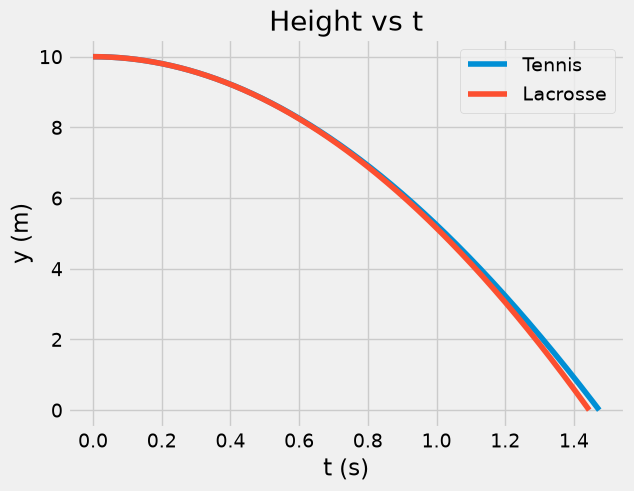

In [47]:
t = np.linspace(0, 2, 20001)
dt = t[1] - t[0]
num_tennis = np.zeros([len(t), 2])
num_lacrosse = np.zeros([len(t), 2])
num_tennis[0] = [10, 0]
num_lacrosse[0] = [10, 0]

for i in range(len(t)-1):
    num_tennis[i+1] = eulerstep(num_tennis[i], fall_drag, dt)
    num_lacrosse[i+1] = eulerstep(num_lacrosse[i], lacrosse_drag, dt)

for name, num_sol in [('Tennis', num_tennis), ('Lacrosse', num_lacrosse)]:
    i = np.nonzero(num_sol[:,0] <= 0)[0][0]
    t_ground = t[i-1] - num_sol[i-1,0]*dt/(num_sol[i,0]-num_sol[i-1,0])
    print(f"{name} ball reaches the ground at {t_ground:.4f} s")
    plt.plot(t[:i+1], num_sol[:i+1,0], label=name)

plt.xlabel('t (s)')
plt.ylabel('y (m)')
plt.title('Height vs t')
plt.legend()

I used the middle of each diameter and mass range, with C_d = 0.51 for both balls. The lacrosse ball lands first because drag has less effect on its acceleration.

**2.** A pendulum that swings in small angles follows a $\theta_0 \cos
\omega t$ where $\theta_0$ is the initial angle that its released from
rest and $\omega$ is the natural frequency of the pendulum. The
underlying differential equation is 

$\ddot{\theta} = -\frac{g}{L}\cos\theta$

a. Create a `pendulum` fuction that returns $[\dot{\theta},~\ddot{\theta}]$ when its given $[\theta,~\dot{\theta}]$

b. Integrate the `pendulum` function for 2 periods of oscillation given initial conditions of $y_0 = [\frac{\pi}{6}~rad,~0~rad/s]$, $g = 9.81~m/s^2$, and $L = 1~m$. Plot the angle as a function of time, $\theta-vs-t$.

In [48]:
#a
def pendulum(y, g=9.81, L=1):
    theta, dtheta = y
    derivs = np.array([dtheta, -g/L*np.sin(theta)])
    return derivs

def rk2_step(state, rhs, dt):
    mid_state = state + rhs(state)*dt/2
    next_state = state + rhs(mid_state)*dt
    return next_state

I used sin(theta), as shown in the supplied derivative.

Text(0.5, 1.0, 'Pendulum for two small-angle periods')

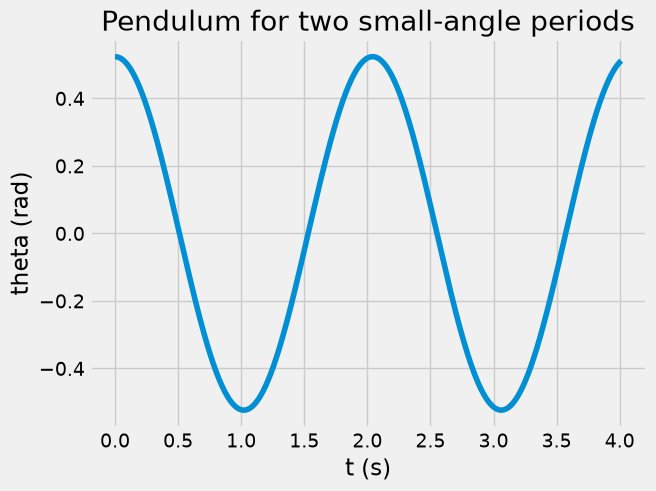

In [49]:
#b
g = 9.81
L = 1
period = 2*np.pi*np.sqrt(L/g)
t = np.linspace(0, 2*period, 2001)
dt = t[1] - t[0]
num_pendulum = np.zeros([len(t), 2])
num_pendulum[0] = [np.pi/6, 0]

for i in range(len(t)-1):
    num_pendulum[i+1] = rk2_step(num_pendulum[i], pendulum, dt)

plt.plot(t, num_pendulum[:,0])
plt.xlabel('t (s)')
plt.ylabel('theta (rad)')
plt.title('Pendulum for two small-angle periods')

## Problems [Part 3](./03_Get_Oscillations.md)

**1.** Show that the implicit Heun's method has the same second order convergence as the Modified Euler's method. _Hint: you can use the same code from above to create the log-log plot to get the error between $2\cos(\omega t)$ and the `heun_step` integration. Use the same initial conditions x(0) = 2 m and v(0)=0m/s and the same RHS function, `springmass`.

In [50]:
def springmass(state):
    derivs = np.array([state[1], -w**2*state[0]])
    return derivs

def heun_step(state, rhs, dt, etol=1e-10, maxiters=100):
    next_state = state + rhs(state)*dt
    for n in range(maxiters):
        next_state_old = next_state
        next_state = state + (rhs(state)+rhs(next_state))/2*dt
        if np.max(np.abs(next_state-next_state_old)) < etol:
            break
    return next_state

Modified Euler slope: 2.001
Implicit Heun slope: 1.999


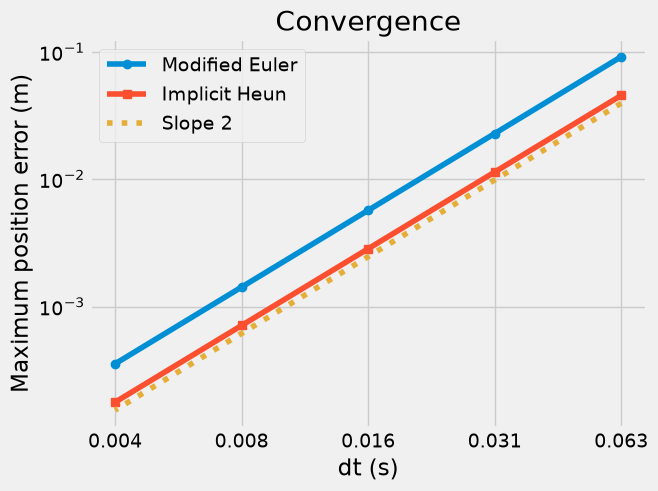

In [51]:
w = 2
period = 2*np.pi/w
T = 3*period
steps = np.array([150, 300, 600, 1200, 2400])
dt_values = T/steps
error_rk2 = np.zeros(len(steps))
error_heun = np.zeros(len(steps))

for j, N in enumerate(steps):
    t = np.linspace(0, T, N+1)
    dt = t[1] - t[0]
    num_rk2 = np.zeros([N+1, 2])
    num_heun = np.zeros([N+1, 2])
    num_rk2[0] = [2, 0]
    num_heun[0] = [2, 0]

    for i in range(N):
        num_rk2[i+1] = rk2_step(num_rk2[i], springmass, dt)
        num_heun[i+1] = heun_step(num_heun[i], springmass, dt)

    x_an = 2*np.cos(w*t)
    error_rk2[j] = np.max(np.abs(num_rk2[:,0]-x_an))
    error_heun[j] = np.max(np.abs(num_heun[:,0]-x_an))

slope_rk2 = np.polyfit(np.log(dt_values), np.log(error_rk2), 1)[0]
slope_heun = np.polyfit(np.log(dt_values), np.log(error_heun), 1)[0]
print(f"Modified Euler slope: {slope_rk2:.3f}")
print(f"Implicit Heun slope: {slope_heun:.3f}")

plt.loglog(dt_values, error_rk2, 'o-', label='Modified Euler')
plt.loglog(dt_values, error_heun, 's-', label='Implicit Heun')
plt.loglog(dt_values, 10*dt_values**2, ':', label='Slope 2')
plt.xticks(dt_values, [f'{dt:.3f}' for dt in dt_values])
plt.minorticks_off()
plt.xlabel('dt (s)')
plt.ylabel('Maximum position error (m)')
plt.title('Convergence')
plt.legend()

Both slopes are close to 2, so both methods have second order convergence. I used the maximum position error over the three periods.

![A lumped mass connected to a spring and
damper](../images/damped-spring.png)

**2.** In the image above, you have a spring, mass, _and damper_. A damper is designed to slow down a moving object. These devices are typical in automobiles, mountain bikes, doors, any place where oscillations may not be desired, but motion is required. The new differential equation, if F(t)=0, that results from this addition is

$\ddot{x} = -\frac{b}{m}\dot{x} -\frac{k}{m}x$

or keeping our _natural frequency_ above, 

$\ddot{x} = -\zeta\omega\dot{x} -\omega^2x$

where $\zeta$ is a new constant called the __damping ratio__ of a system. When $\zeta\gt 1$, there are no oscillations and when $0<\zeta<1$ the system oscillates, but decays to v=0 m/s eventually. 

Create the system of equations that returns the right hand side (RHS) of the state equations, e.g. $\mathbf{\dot{y}} = f(\mathbf{y}) = RHS$

Use $\omega = 2$ rad/s and $\zeta = 0.2$.

In [52]:
def smd(state):
    w = 2
    zeta = 0.2
    x, v = state
    derivs = np.array([v, -zeta*w*v - w**2*x])
    return derivs

**3.** Use three methods to integrate your `smd` function for 3 time periods of oscillation and initial conditions x(0)=2 m and v(0)=0 m/s. Plot the three solutions on one graph with labels. 

a. Euler integration

b. second order Runge Kutta method (modified Euler method)

c. the implicit Heun's method

How many time steps does each method need to converge to the same results? _Remember that each method has a certain convergence rate_

Euler: 12800 time steps, maximum error = 0.00545 m
Modified Euler: 400 time steps, maximum error = 0.00273 m
Implicit Heun: 200 time steps, maximum error = 0.00545 m


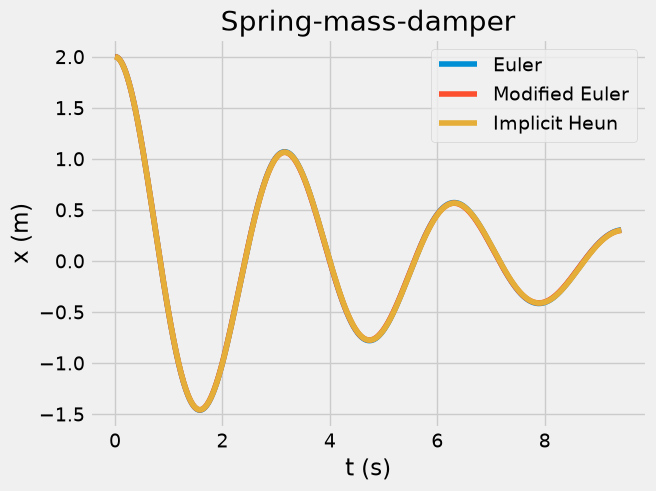

In [53]:
w = 2
zeta = 0.2
period = 2*np.pi/w
T = 3*period
steps = [100, 200, 400, 800, 1600, 3200, 6400, 12800, 25600]
methods = [('Euler', eulerstep), ('Modified Euler', rk2_step), ('Implicit Heun', heun_step)]
tol = 0.01

for name, method in methods:
    for N in steps:
        t = np.linspace(0, T, N+1)
        dt = t[1] - t[0]
        num_sol = np.zeros([N+1, 2])
        num_sol[0] = [2, 0]

        for i in range(N):
            num_sol[i+1] = method(num_sol[i], smd, dt)

        a = zeta*w/2
        wd = np.sqrt(w**2-a**2)
        x_an = 2*np.exp(-a*t)*(np.cos(wd*t)+a/wd*np.sin(wd*t))
        error = np.max(np.abs(num_sol[:,0]-x_an))
        if error < tol:
            break

    print(f"{name}: {N} time steps, maximum error = {error:.5f} m")
    plt.plot(t, num_sol[:,0], label=name)

plt.xlabel('t (s)')
plt.ylabel('x (m)')
plt.title('Spring-mass-damper')
plt.legend()

I considered the solutions converged when the maximum position error was below 0.01 m. The printed counts are the first tested step counts that meet this tolerance. Euler needs many more steps because it is first order, while modified Euler and implicit Heun are second order.

## Problems [Part 3](./04_Getting_to_the_root.md)

**1.** One of the main benefits of a bracketing method is the stability of solutions. Open methods are not always stable. Here is an example. One way engineers and data scientists model the probability of failure is with a [sigmoid function e.g. this Challenger O-ring case study](https://byuistats.github.io/M325_Hathaway/textbook/challengerLogisticReg.html)

$$\begin{equation}
    \sigma(T) = \frac{e^{a_0-a_1 T}}{1+e^{a_0-a_1 T}}
\end{equation}$$

The Challenger explosion was a terrible incident that occurred due to the failure of an O-ring. The post-mortem data analysis showed that at low temperatures the O-rings were brittle and more likely to fail. You can use the function $\sigma(T)$ to determine the point at which there is a 50\% chance of O-ring failure. Using the pass-fail data, the two constants are

$a_0 = 15.043$

$a_1 = 0.232$

a. Plot the function $\sigma(T)$ for $T=0-100^{o}F$. Where do you see the function cross 50\% (0.5)?

b. Create two functions `f_T` and `dfdT` where `f_T`=$f(T)=\sigma(T) - 0.5$ and `dfdT`=$\frac{df}{dT}$

c. Use the `incsearch` and `newtraph` functions to find the root of f(T). When does Newton-Raphson fail to converge? Why does it fail? _Hint: if you're stuck here, take a look at this [youtube video finding an interval of convergence for the Newton-Raphson method](https://youtu.be/zyXRo8Qjj0A). Look at the animation of how the method converges and diverges._

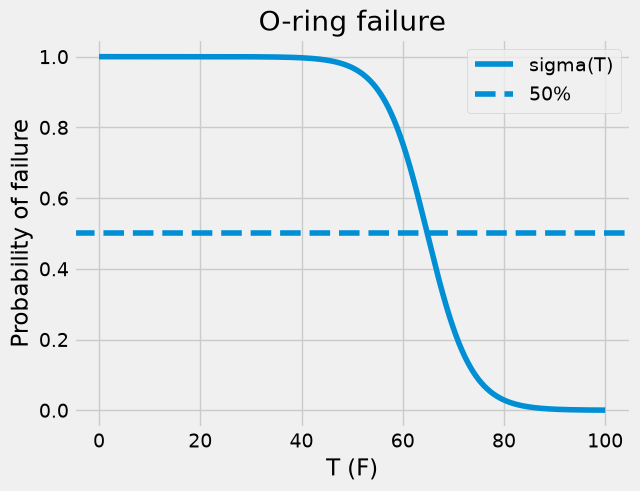

In [54]:
#a
T = np.linspace(0, 100, 1001)
a0 = 15.043
a1 = 0.232
sigma = np.exp(a0-a1*T)/(1+np.exp(a0-a1*T))
plt.plot(T, sigma, label='sigma(T)')
plt.axhline(0.5, linestyle='--', label='50%')
plt.xlabel('T (F)')
plt.ylabel('Probability of failure')
plt.title('O-ring failure')
plt.legend()

In [55]:
#b
def f_T(T):
    exp_T = np.exp(15.043-0.232*T)
    return exp_T/(1+exp_T) - 0.5

def dfdT(T):
    sigma = f_T(T) + 0.5
    return -0.232*sigma*(1-sigma)

def incsearch(func, xmin, xmax, ns=50):
    x = np.linspace(xmin, xmax, ns)
    f = func(x)
    i_zeros = np.nonzero(np.diff(np.sign(f)) != 0)[0]
    xb = np.array([x[i_zeros], x[i_zeros+1]])
    return xb

def newtraph(func, dfunc, x0, es=0.0001, maxit=50):
    xr = float(x0)
    ea = np.inf
    for n in range(maxit):
        with np.errstate(over='ignore', invalid='ignore'):
            slope = dfunc(xr)
        if not np.isfinite(slope) or abs(slope) < 1e-14:
            return np.nan, [np.nan, ea, n]
        xrold = xr
        xr = xrold - func(xrold)/slope
        ea = abs((xr-xrold)/xr)*100 if xr != 0 else abs(xr-xrold)*100
        if ea < es:
            break
    return xr, [func(xr), ea, n+1]

In [56]:
#c
brackets = incsearch(f_T, 0, 100)
print(f"Default incremental search bracket: {brackets[:,0]} F")
brackets = incsearch(f_T, 0, 100, ns=1001)
print(f"Incremental search bracket: {brackets[:,0]} F")
root, out = newtraph(f_T, dfdT, 60)
print(f"50% failure temperature: {root:.4f} F")

for guess in [0, 20, 50, 55, 56, 60, 65, 70, 75, 80, 100]:
    root, out = newtraph(f_T, dfdT, guess)
    if np.isfinite(root) and abs(out[0]) < 1e-8:
        print(f"Initial guess {guess} F: {root:.4f} F")
    else:
        print(f"Initial guess {guess} F: failed to converge")

Default incremental search bracket: [63.26530612 65.30612245] F
Incremental search bracket: [64.8 64.9] F
50% failure temperature: 64.8405 F
Initial guess 0 F: failed to converge
Initial guess 20 F: failed to converge
Initial guess 50 F: failed to converge
Initial guess 55 F: failed to converge
Initial guess 56 F: 64.8405 F
Initial guess 60 F: 64.8405 F
Initial guess 65 F: 64.8405 F
Initial guess 70 F: 64.8405 F
Initial guess 75 F: failed to converge
Initial guess 80 F: failed to converge
Initial guess 100 F: failed to converge


The curve crosses 0.5 at about 64.84 F. Newton-Raphson converges for the tested guesses of 56, 60, 65 and 70 F, but fails for the others. At 55 F it still diverges, while 56 F works. Far from the root, the curve is almost flat, so dividing by a very small derivative produces a large step away from the root. Incremental search still brackets the crossing.

**2.** In the [Shooting Method
   example](https://cooperrc.github.io/computational-mechanics/module_03/04_Getting_to_the_root.html#shooting-method), you determined the initial velocity after the first
   bounce by specifying the beginning y(0) and end y(T) for an object
   subject to gravity and drag. Repeat this analysis for the time period
   just after the second bounce and just before the third bounce. The
   indices are given below for t[1430:2051] = 1.43-2.05 seconds.

a. What is the velocity just after the second bounce?

b. What is the coefficient of restitution for the second bounce? _Hint: use the ratio of the last velocity from above to the initial velocity calculated here._

1.4300000000009008 2.051000000004969


Text(0.5, 1.0, 'Second bounce interval')

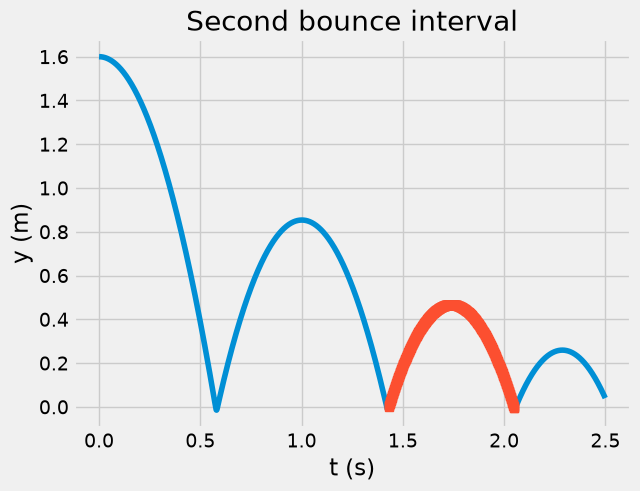

In [57]:
filename = '../data/fallingtennisball02.txt'
t, y = np.loadtxt(filename, usecols=[0,1], unpack=True)
i0=1430
ie=2051
print(t[i0],t[ie])
plt.plot(t,y)
plt.plot(t[i0:ie],y[i0:ie],'s')
plt.xlabel('t (s)')
plt.ylabel('y (m)')
plt.title('Second bounce interval')

In [58]:
def tennis_drag(state):
    return fall_drag(state, C_d=0.47, R=0.0661/2)

def bounce_solution(v0, tbounce, ybounce):
    num_sol = np.zeros([len(tbounce), 2])
    num_sol[0] = [ybounce[0], v0]
    for i in range(len(tbounce)-1):
        dt = tbounce[i+1] - tbounce[i]
        num_sol[i+1] = rk2_step(num_sol[i], tennis_drag, dt)
    return num_sol

def f_v(v0, tbounce, ybounce):
    num_sol = bounce_solution(v0, tbounce, ybounce)
    return num_sol[-1,0] - ybounce[-1]

def mod_secant(func, dx, x0, es=0.0001, maxit=50):
    xr = x0
    for n in range(maxit):
        xrold = xr
        dfunc = (func(xr+dx)-func(xr))/dx
        xr = xr - func(xr)/dfunc
        ea = abs((xr-xrold)/xr)*100 if xr != 0 else abs(xr-xrold)*100
        if ea < es:
            break
    return xr, [func(xr), ea, n+1]

Velocity just after the second bounce: 3.0428 m/s
Velocity just before the second bounce: -4.1044 m/s
Coefficient of restitution for the second bounce: 0.7413


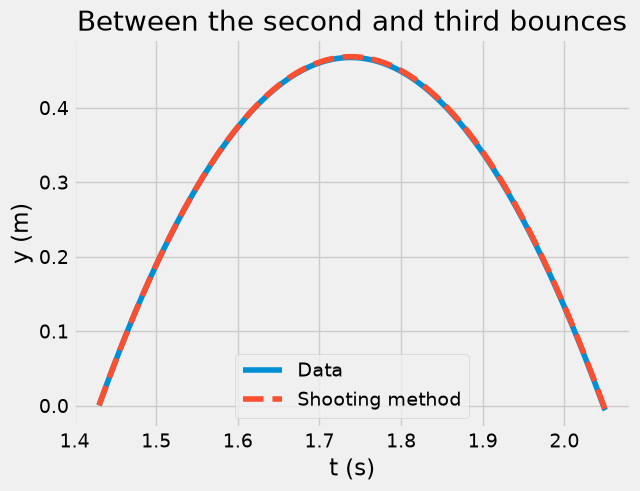

In [59]:
#a
tbounce1 = t[580:1425]
ybounce1 = y[580:1425]
tbounce2 = t[i0:ie]
ybounce2 = y[i0:ie]

def f_v1(v0):
    return f_v(v0, tbounce1, ybounce1)

def f_v2(v0):
    return f_v(v0, tbounce2, ybounce2)

v01, out1 = mod_secant(f_v1, 0.0001, 4, es=0.000001)
v02, out2 = mod_secant(f_v2, 0.0001, 3, es=0.000001)
num_bounce1 = bounce_solution(v01, tbounce1, ybounce1)
num_bounce2 = bounce_solution(v02, tbounce2, ybounce2)
print(f"Velocity just after the second bounce: {v02:.4f} m/s")

#b
v_before = num_bounce1[-1,1]
cof_rest = -v02/v_before
print(f"Velocity just before the second bounce: {v_before:.4f} m/s")
print(f"Coefficient of restitution for the second bounce: {cof_rest:.4f}")

plt.plot(tbounce2, ybounce2, label='Data')
plt.plot(tbounce2, num_bounce2[:,0], '--', label='Shooting method')
plt.xlabel('t (s)')
plt.ylabel('y (m)')
plt.title('Between the second and third bounces')
plt.legend()